In [2]:
import numpy as np #linear algebra
import pandas as pd # data processing
import matplotlib.pyplot as plt
import seaborn as sns


In [8]:
df  = pd.read_csv('wine_data.csv')


In [9]:
df

,1,14.23,1.71,2.43,15.6,127,2.8,3.06,.28,2.29,5.64,1.04,3.92,1065
0,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
1,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
2,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
3,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735
4,1,14.20,1.76,2.45,15.2,112,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
172,3,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740
173,3,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750
174,3,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835
175,3,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840


In [13]:
df = pd.read_csv('wine_data.csv', header = None, usecols=[0, 1, 2]) 
df.columns = ['Class label', 'Alcohol', 'Malic acid']

In [14]:
df

,Class label,Alcohol,Malic acid
0,1,14.23,1.71
1,1,13.20,1.78
2,1,13.16,2.36
3,1,14.37,1.95
4,1,13.24,2.59
...,...,...,...
173,3,13.71,5.65
174,3,13.40,3.91
175,3,13.27,4.28
176,3,13.17,2.59


<Axes: xlabel='Alcohol', ylabel='Density'>

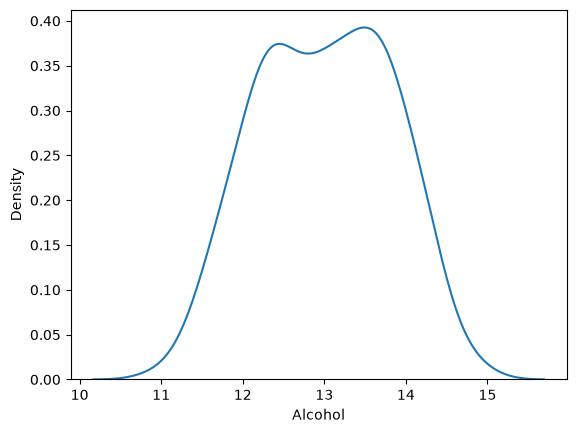

In [15]:
sns.kdeplot(df['Alcohol'])

<Axes: xlabel='Malic acid', ylabel='Density'>

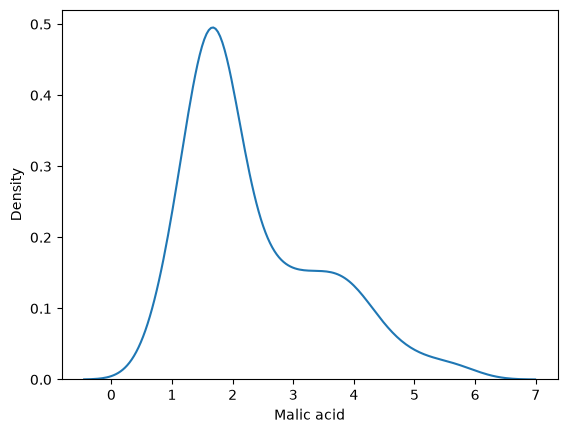

In [16]:
sns.kdeplot(df['Malic acid'])

<Axes: xlabel='Alcohol', ylabel='Malic acid'>

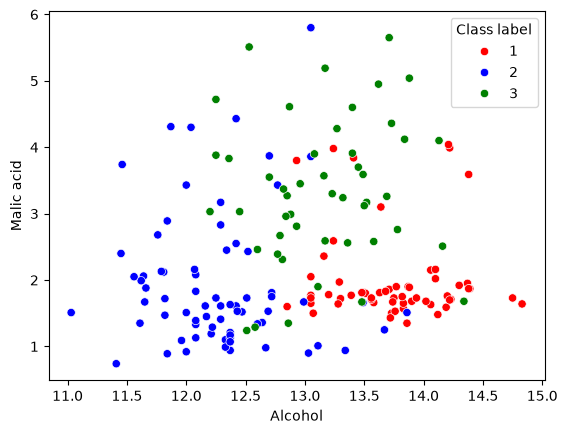

In [21]:
color_dict = {1: 'red', 3: 'green', 2: 'blue'}

sns.scatterplot(
    x=df['Alcohol'],
    y=df['Malic acid'],
    hue=df['Class label'],
    palette=color_dict
)

In [27]:
# Drop Class label from X because it is the target we want to predict,
# then take it separately as y (the target/answer).

X_train, X_test, y_train, y_test = train_test_split(
    df.drop('Class label', axis=1),  # X = features (Alcohol, Malic acid)
    df['Class label'],               # y = target (Class label)
    test_size=0.3,
    random_state=0
)
X_train.shape, X_test.shape

((124, 2), (54, 2))

In [31]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler() # create an empty object named scaler

#so here till now scaler is empty object and we pass only X-train data and then we fit it and store in scaler
scaler.fit(X_train) # here we find min and max value from fit 

#transform both train and test input data
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [34]:
# Convert scaled data back to a DataFrame and colums = X_train.columns means use X_train's original column names
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

In [35]:
np.round(X_train)

,Alcohol,Malic acid
22,14.0,2.0
108,12.0,1.0
175,13.0,4.0
145,13.0,4.0
71,14.0,2.0
...,...,...
103,12.0,2.0
67,12.0,1.0
117,12.0,2.0
47,14.0,2.0


In [37]:
# Get summary statistics and round the values to 1 decimal place
np.round(X_train.describe(), 1)

,Alcohol,Malic acid
count,124.0,124.0
mean,13.0,2.4
std,0.8,1.1
min,11.0,0.9
25%,12.4,1.6
50%,13.0,1.9
75%,13.6,3.2
max,14.8,5.6


In [40]:
np.round(X_train_scaled.describe(),1 ) # here you can see min value wll be 0 and max value will be 1 after min-max scaling

,Alcohol,Malic acid
count,124.0,124.0
mean,0.5,0.3
std,0.2,0.2
min,0.0,0.0
25%,0.4,0.2
50%,0.5,0.2
75%,0.7,0.5
max,1.0,1.0


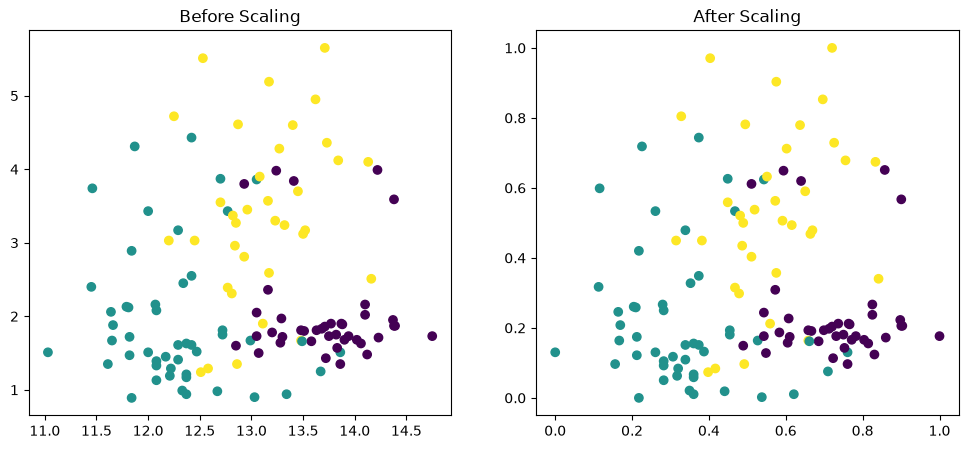

In [41]:
fig, (ax1, ax2) = plt.subplots(ncols =2, figsize = (12, 5))

ax1.scatter(X_train['Alcohol'], X_train['Malic acid'], c= y_train)
ax1.set_title('Before Scaling')
ax2.scatter(X_train_scaled['Alcohol'], X_train_scaled['Malic acid'], c=y_train)
ax2.set_title('After Scaling')
plt.show()

<Axes: title={'center': 'After Scaling'}, xlabel='Alcohol', ylabel='Density'>

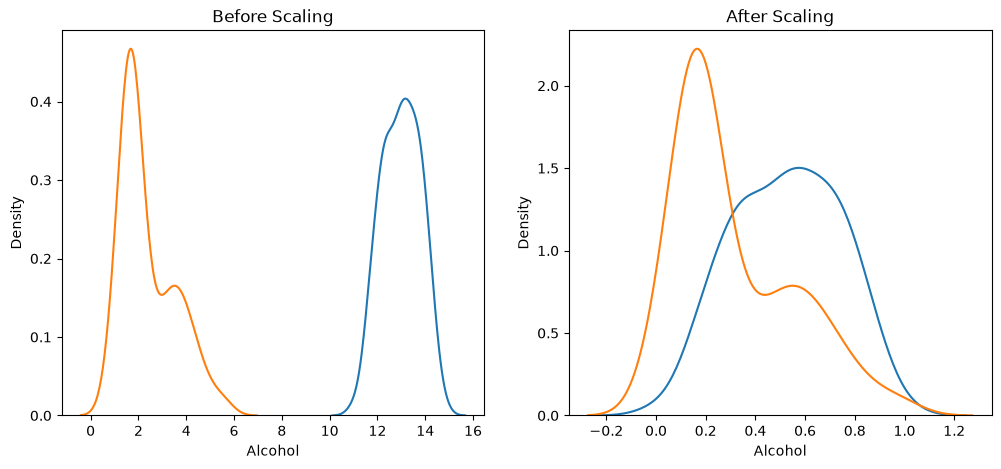

In [42]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize = (12,5))

#bfore scaling
ax1.set_title('Before Scaling')
sns.kdeplot(X_train['Alcohol'], ax = ax1)
sns.kdeplot(X_train['Malic acid'], ax = ax1)

# after scalibg
ax2.set_title('After Scaling')
sns.kdeplot(X_train_scaled['Alcohol'], ax = ax2)
sns.kdeplot(X_train_scaled['Malic acid'], ax= ax2)

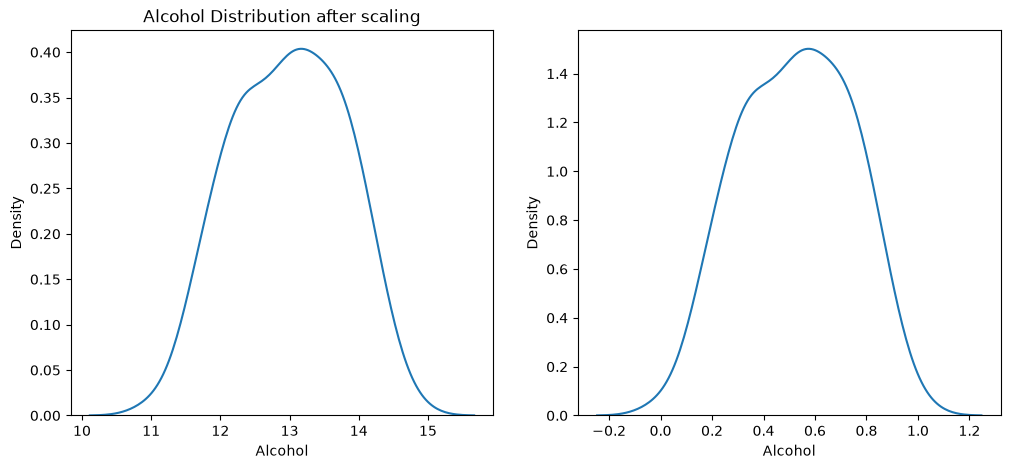

In [45]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12,5))

# before sclaing
ax1.set_title('Alcohol Distribution before scaling')
sns.kdeplot(X_train['Alcohol'], ax= ax1)


# after sclaing
ax1.set_title('Alcohol Distribution after scaling')
sns.kdeplot(X_train_scaled['Alcohol'], ax= ax2)
plt.show()

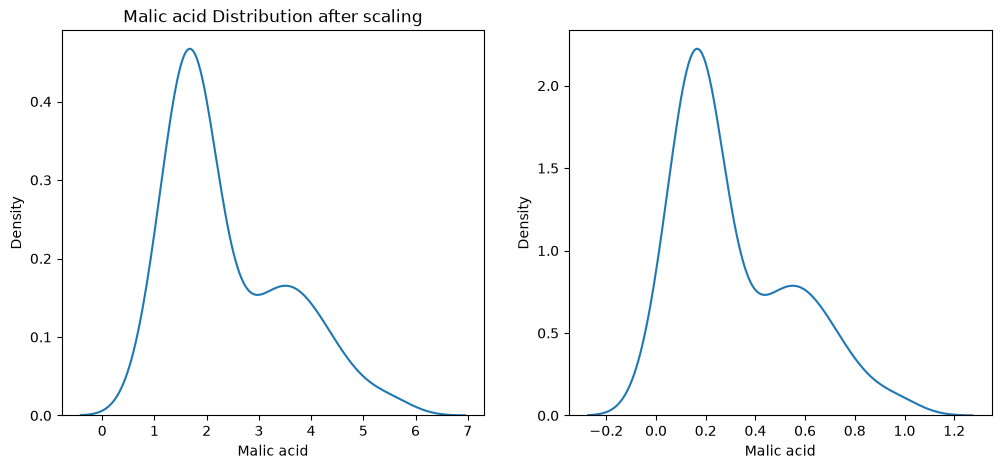

In [46]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12,5))

# before sclaing
ax1.set_title('Malic acid Distribution before scaling')
sns.kdeplot(X_train['Malic acid'], ax= ax1)


# after sclaing
ax1.set_title('Malic acid Distribution after scaling')
sns.kdeplot(X_train_scaled['Malic acid'], ax= ax2)
plt.show()